# 03. Stacked ensemble

**Thesis:** Machine-Learning Prediction of Shear-Wave Velocity in the Dampier Sub-basin: Accuracy, Errors and Applications (D. Aldosaimani, Curtin University, 2026)

**What this notebook does:** Combines the Linear, Ridge, Lasso and MLP models in a stacked ensemble, tested with the same LOWO validation, and applies it to the three wells without Vs.

**Used in:** Section 4.1

**Needs:** `DATA_DIR` and `LAS_DIR` (set in the Settings cell below)

**Writes:** LOWO results table

## 1. Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import lasio
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import StackingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## Settings

In [ ]:
# ---- Settings: set these paths before running ----
DATA_DIR    = Path("../data/processed")   # the eight *_with_formation.csv files (well logs with formation names)
LAS_DIR     = Path("../data/las")         # the eight *_LQC.las files from NOPIMS (project ENO0810814A)
RESULTS_DIR = Path("../results")          # results tables are written here
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load and combine all 8 wells



In [2]:
data_dir = DATA_DIR

well_logs = {}

for csv_file in sorted(data_dir.glob("*.csv")):
    well_name = csv_file.stem
    df = pd.read_csv(csv_file)
    df.insert(0, "Well Name", well_name)
    well_logs[well_name] = df
    print(f"{well_name}: {len(df)} samples")

data_df = pd.concat(well_logs.values(), ignore_index=True)
print(f"\nLoaded {len(well_logs)} wells, {len(data_df)} total samples")

wells = data_df['Well Name'].unique()

Angel_1_with_formation: 3657 samples
Angel_3_with_formation: 15205 samples
Egret_2_with_formation: 5287 samples
Lambert_8B_with_formation: 9385 samples
Nereus_1_with_formation: 9273 samples
Persephone_1_with_formation: 9706 samples
Seraph_1_with_formation: 1470 samples
Wanaea_11A_with_formation: 3087 samples

Loaded 8 wells, 57070 total samples


In [3]:
FIGURES_DIR = Path("figures_stacked_ensemble")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 2b. Data cleaning (final)

Same two cleaning cells as the Regression notebook (updated_8), so every model and every result uses exactly the same rows:

1. **Remove impossible Vp:** readings faster than the fastest Vp the local minerals could have at zero porosity (Voigt bound of quartz, calcite and illite, illite given quartz properties; Mavko et al., 2009).
2. **Keep only real, unchanged measured Vs** in the 5 measured wells: `VS_ORG` exists in the LAS file and `VS_EDITED_V2` is within 2% of it.

Washouts are kept (tested in the Regression notebook), and no rule based on Vs itself is used. The 3 modelled-only wells only go through step 1.


In [4]:
# --- Remove physically impossible Vp (faster than the rock's own minerals) ---
# Upper limit at each depth = stiffest possible (Voigt) mix of its minerals at zero porosity.
# Clay (illite) is given the stiffness of quartz. Real clay is softer, so this limit is
# deliberately too high: it can only remove readings that no real rock could produce.
# Mineral properties from Mavko et al. (2009): K and mu in GPa, rho in g/cc
QUARTZ  = dict(K=37.0, mu=44.0, rho=2.65)     # solid quartz:  Vp ~ 6010 m/s
CALCITE = dict(K=76.8, mu=32.0, rho=2.71)     # solid calcite: Vp ~ 6640 m/s
REMOVE_IMPOSSIBLE_VP = True

def p_modulus(mineral):                        # P-wave modulus M = K + 4/3 mu
    return mineral['K'] + 4 / 3 * mineral['mu']

solid = data_df[['QUARTZ_COMBINER', 'CALCITE_COMBINER', 'ILLITE_COMBINER']].sum(axis=1)
f_calcite = data_df['CALCITE_COMBINER'] / solid      # calcite fraction of the solid rock
f_other = 1 - f_calcite                               # quartz + illite (both given quartz properties)

M   = f_other * p_modulus(QUARTZ) + f_calcite * p_modulus(CALCITE)      # GPa
rho = f_other * QUARTZ['rho'] + f_calcite * CALCITE['rho']               # g/cc
data_df['VP_LIMIT'] = np.sqrt(M / rho) * 1000                             # km/s -> m/s
data_df['vp_impossible'] = data_df['VP_EDITED'] > data_df['VP_LIMIT']

bad = data_df[data_df['vp_impossible']]
print(f"Depths with Vp faster than their minerals allow: {len(bad)}")
display(bad[['Well Name', 'MD', 'Formation', 'VP_EDITED', 'VP_LIMIT']].round(1))

if REMOVE_IMPOSSIBLE_VP:
    data_df = data_df[~data_df['vp_impossible']].reset_index(drop=True)
    print(f"Removed. Rows left: {len(data_df)}")


Depths with Vp faster than their minerals allow: 6


,Well Name,MD,Formation,VP_EDITED,VP_LIMIT
19480,Egret_2_with_formation,2720.5,Withnell Fm,7819.4,6289.8
19644,Egret_2_with_formation,2745.5,Withnell Fm,7181.5,6609.1
19645,Egret_2_with_formation,2745.6,Withnell Fm,7411.0,6609.6
19646,Egret_2_with_formation,2745.8,Withnell Fm,7115.9,6609.4
19749,Egret_2_with_formation,2761.5,Withnell Fm,6502.3,6437.3
53598,Seraph_1_with_formation,2977.1,Angel Fm,6146.5,6008.4


Removed. Rows left: 57064


In [5]:
# --- Keep only real measured Vs (compare VS_EDITED_V2 with VS_ORG from the LAS files) ---

MEASURED_ONLY = True   # remove depths where Vs is not a real measurement
DROP_EDITED   = True   # also remove depths where SLB changed the measured Vs by more than EDIT_TOL
EDIT_TOL      = 0.02   # 2%, same threshold as the checks in Part 3

measured_names = ['Egret_2', 'Lambert_8B', 'Nereus_1', 'Persephone_1', 'Seraph_1']
data_df['VS_ORG'] = np.nan             # modelled-only wells stay empty

for w in measured_names:
    d = lasio.read(list(LAS_DIR.rglob(f"{w}_LQC.las"))[0]).df().reset_index()
    d.columns = d.columns.str.upper()
    d = d.rename(columns={d.columns[0]: 'MD'})
    d = d[['MD', 'VS_ORG']].sort_values('MD')

    idx = data_df['Well Name'].str.contains(w)
    sub = data_df.loc[idx, ['MD']].reset_index().sort_values('MD')
    merged = pd.merge_asof(sub, d, on='MD', direction='nearest', tolerance=0.1)
    data_df.loc[merged['index'], 'VS_ORG'] = merged['VS_ORG'].values

has_org = data_df['VS_ORG'].notna()
edited = has_org & ((data_df['VS_EDITED_V2'] - data_df['VS_ORG']).abs() / data_df['VS_ORG'] > EDIT_TOL)
data_df['VS_MEASURED'] = (has_org & ~edited) if DROP_EDITED else has_org

# Summary per measured well
in_measured_well = data_df['Well Name'].str.contains('|'.join(measured_names))
names = data_df.loc[in_measured_well, 'Well Name']
summary = pd.DataFrame({
    'rows': names.value_counts().sort_index(),
    '% real, unchanged': (100 * (has_org & ~edited)[in_measured_well].groupby(names).mean()).round(1),
    '% real, edited by SLB': (100 * edited[in_measured_well].groupby(names).mean()).round(1),
    '% modelled (no VS_ORG)': (100 * (~has_org)[in_measured_well].groupby(names).mean()).round(1),
})
print(summary)

if MEASURED_ONLY:
    data_df = data_df[~in_measured_well | data_df['VS_MEASURED']].reset_index(drop=True)
    print("\nRows kept per well:")
    print(data_df.groupby('Well Name').size())

    # Check: every row left in the 5 measured wells is a real measurement
    in_measured_well = data_df['Well Name'].str.contains('|'.join(measured_names))
    assert data_df.loc[in_measured_well, 'VS_MEASURED'].all()
    print("\nCheck passed: all rows left in the 5 measured wells are real measured Vs")


                             rows  % real, unchanged  % real, edited by SLB  \
Well Name                                                                     
Egret_2_with_formation       5282               85.3                   14.1   
Lambert_8B_with_formation    9385              100.0                    0.0   
Nereus_1_with_formation      9273               96.5                    2.9   
Persephone_1_with_formation  9706               32.2                    1.0   
Seraph_1_with_formation      1469               53.3                    2.2   

                             % modelled (no VS_ORG)  
Well Name                                            
Egret_2_with_formation                          0.6  
Lambert_8B_with_formation                       0.0  
Nereus_1_with_formation                         0.6  
Persephone_1_with_formation                    66.8  
Seraph_1_with_formation                        44.5  

Rows kept per well:
Well Name
Angel_1_with_formation          3657


## 3. Define well groups (measured vs modelled-only)

This split controls which wells are allowed into LOWO training and testing (Section 5) — not just how results get reported at the end.

In [6]:
measured_wells = [
    'Egret_2_with_formation',
    'Lambert_8B_with_formation',
    'Nereus_1_with_formation',
    'Persephone_1_with_formation',
    'Seraph_1_with_formation',
]

modelled_wells = [
    'Angel_1_with_formation',
    'Angel_3_with_formation',
    'Wanaea_11A_with_formation',
]

print("Measured wells (used for LOWO validation):", len(measured_wells))
print("Modelled-only wells (used later in Part 2 only):", len(modelled_wells))

Measured wells (used for LOWO validation): 5
Modelled-only wells (used later in Part 2 only): 3


## 4. Define features and target

5 features. Two changes from the earlier 6-feature set, per Olivia's feedback:

- Resistivity is fed in as `RESD_LOG` (log10 of RESD_EDITED), not the raw ohm-m values. Resistivity is a log-normally distributed quantity, so a log10 transform is standard practice before feeding it into a model.
- `VCL_GEO_QEPP` (clay volume) has been dropped — it's derived from GR_EDITED, so keeping both as separate model inputs double-counts the same information.

In [7]:
data_df['RESD_LOG'] = np.log10(data_df['RESD_EDITED'])

features_reg = [
    'GR_EDITED',
    'RHOB_EDITED',
    'NPHI_EDITED',
    'RESD_LOG',
    'VP_EDITED',
]

target_reg = 'VS_EDITED_V2'

missing = data_df[features_reg + [target_reg]].isna().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values in features/target")

No missing values in features/target


In [8]:
# Lasso alpha for the Lasso base model.
# Copy the value printed in the Regression notebook, Section 8:
#   "Best alpha by mean LOWO RMSE: ..."
# (the old value 4.1753 came from the all-data run, so it no longer applies)
best_alpha = 7.278953843983153   # from the Regression notebook updated_8, Section 8 (printed as 7.2790)

if best_alpha is None:
    raise ValueError("Set best_alpha first: copy it from the Regression notebook, Section 8 (Best alpha by mean LOWO RMSE).")
print("Lasso alpha used in the ensemble:", best_alpha)


Lasso alpha used in the ensemble: 7.278953843983153


## 5. Stacked Ensemble — LOWO cross-validation (5 measured wells)



In [9]:
results = []

for val_well in measured_wells:

    train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == val_well]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])

    base_models = [
        ('linear', LinearRegression()),
        ('ridge', Ridge(alpha=1.0)),
        ('lasso', Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)),
    ]

    model = StackingRegressor(
        estimators=base_models,
        final_estimator=Ridge(alpha=1.0),
        cv=5
    )
    model.fit(X_train, train_df[target_reg])

    pred = model.predict(X_val)

    r2 = r2_score(val_df[target_reg], pred)
    rmse = np.sqrt(mean_squared_error(val_df[target_reg], pred))
    mae = mean_absolute_error(val_df[target_reg], pred)

    results.append({
        'Validation Well': val_well,
        'R2': r2,
        'RMSE': rmse,
        'MAE': mae
    })

results_stack = pd.DataFrame(results)
results_stack['Model'] = 'Stacked Ensemble'
results_stack = results_stack[['Model', 'Validation Well', 'R2', 'RMSE', 'MAE']]
results_stack.to_csv(RESULTS_DIR / 'lowo_stacked_ensemble.csv', index=False)

print("Mean R2:", results_stack['R2'].mean())
print("Mean RMSE:", results_stack['RMSE'].mean())
print("Mean MAE:", results_stack['MAE'].mean())

results_stack

Mean R2: 0.6968507645321548
Mean RMSE: 171.56702990012266
Mean MAE: 135.27325045264433


,Model,Validation Well,R2,RMSE,MAE
0,Stacked Ensemble,Egret_2_with_formation,0.777737,179.427855,119.388910
1,Stacked Ensemble,Lambert_8B_with_formation,0.898296,95.086327,71.631502
2,Stacked Ensemble,Nereus_1_with_formation,0.910532,132.892334,111.427180
3,Stacked Ensemble,Persephone_1_with_formation,-0.043699,310.192415,264.845848
4,Stacked Ensemble,Seraph_1_with_formation,0.941388,140.236219,109.072811


### Diagnostic plot — actual vs predicted Vs, for every measured well

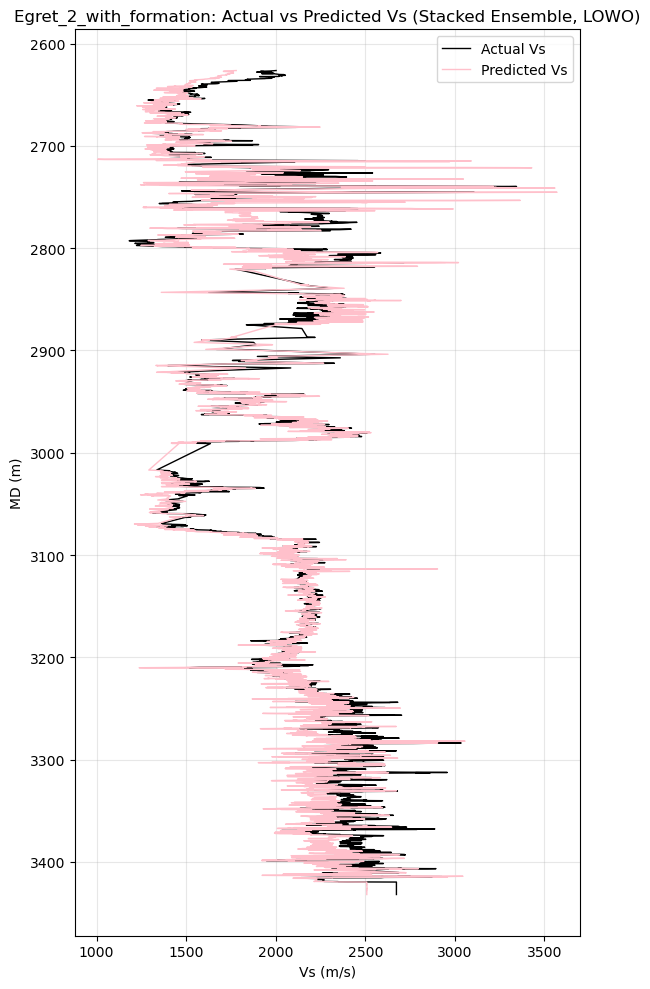

Egret_2_with_formation  R²=0.778  RMSE=179.4 m/s


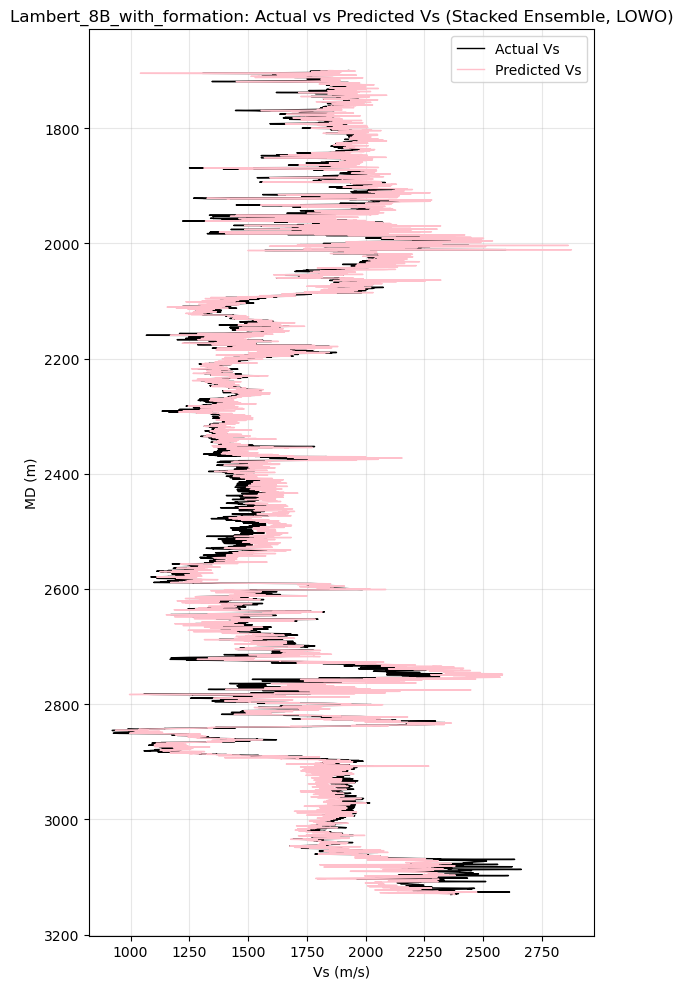

Lambert_8B_with_formation  R²=0.898  RMSE=95.1 m/s


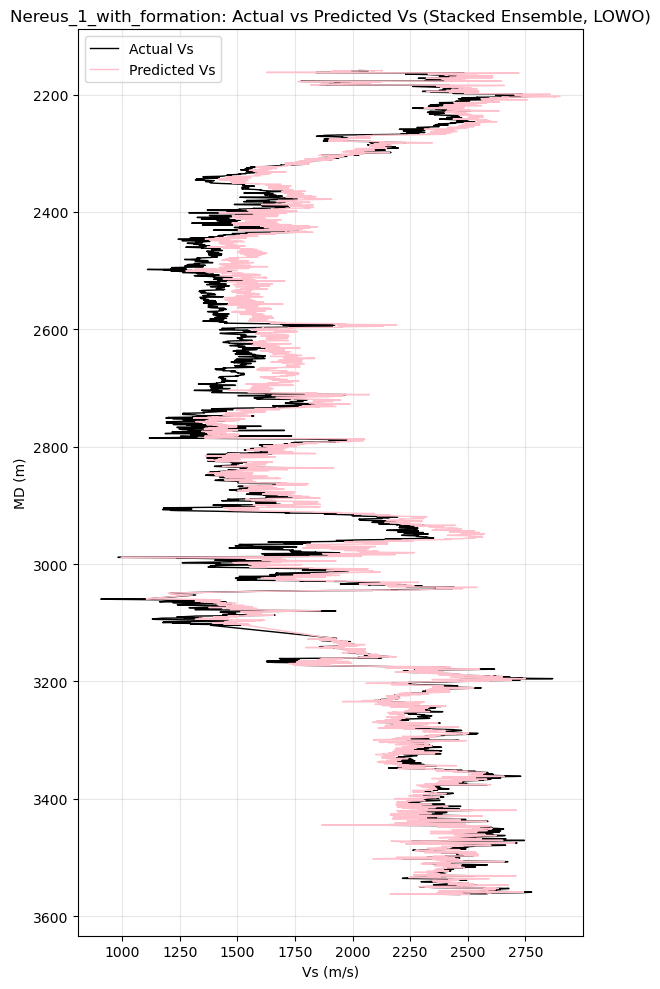

Nereus_1_with_formation  R²=0.911  RMSE=132.9 m/s


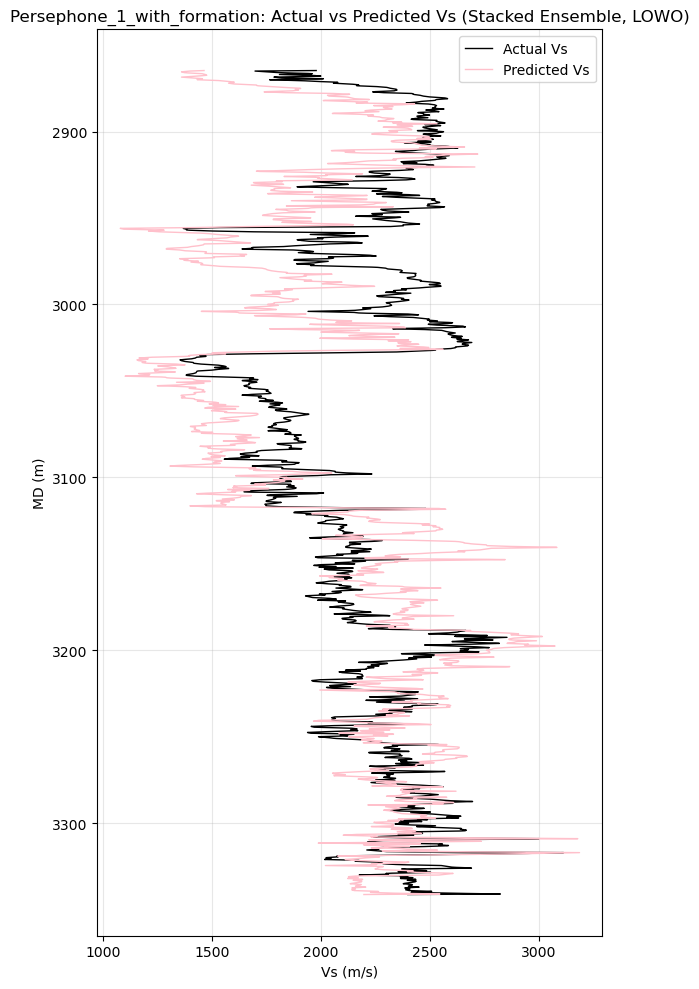

Persephone_1_with_formation  R²=-0.044  RMSE=310.2 m/s


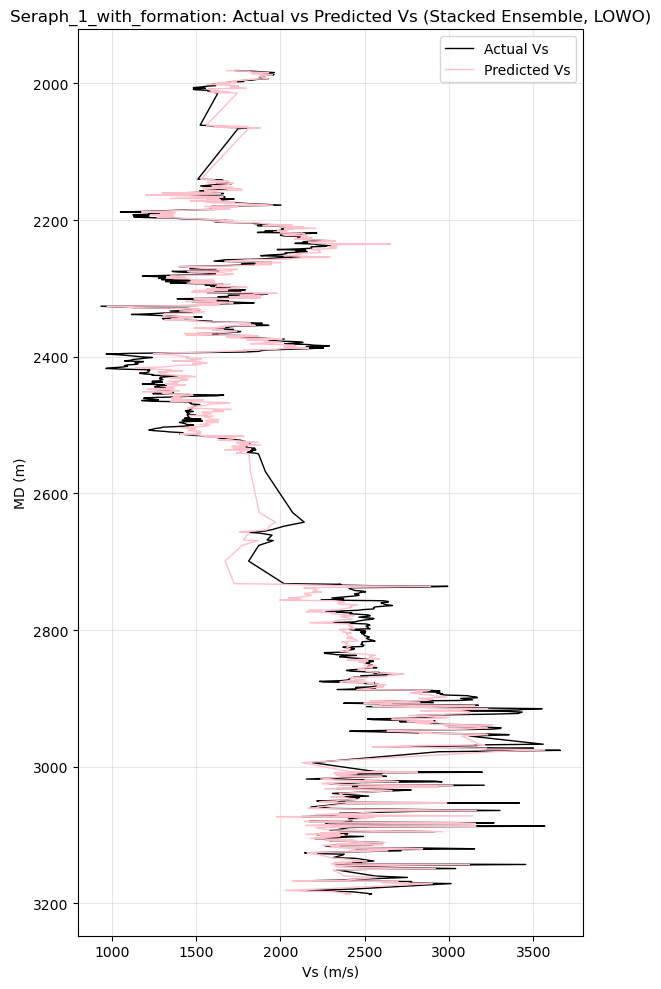

Seraph_1_with_formation  R²=0.941  RMSE=140.2 m/s


In [10]:
for plot_well in measured_wells:

    train_df = data_df[(data_df['Well Name'] != plot_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == plot_well].copy()

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])

    base_models = [
        ('linear', LinearRegression()),
        ('ridge', Ridge(alpha=1.0)),
        ('lasso', Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)),
    ]

    model = StackingRegressor(
        estimators=base_models,
        final_estimator=Ridge(alpha=1.0),
        cv=5
    )
    model.fit(X_train, train_df[target_reg])

    val_df['VS_PRED'] = model.predict(X_val)

    plt.figure(figsize=(6, 10))
    plt.plot(val_df[target_reg], val_df['MD'], label='Actual Vs', color='black', lw=1)
    plt.plot(val_df['VS_PRED'], val_df['MD'], label='Predicted Vs', color='pink', lw=1)
    plt.gca().invert_yaxis()
    plt.xlabel('Vs (m/s)')
    plt.ylabel('MD (m)')
    plt.title(f'{plot_well}: Actual vs Predicted Vs (Stacked Ensemble, LOWO)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"stacked_actual_vs_predicted_{plot_well.replace('_with_formation', '')}.png", dpi=300, bbox_inches='tight')
    plt.show()

    r2 = r2_score(val_df[target_reg], val_df['VS_PRED'])
    rmse = np.sqrt(mean_squared_error(val_df[target_reg], val_df['VS_PRED']))
    print(f"{plot_well}  R²={r2:.3f}  RMSE={rmse:.1f} m/s")

### Diagnostic plot — multi-track well log display, for every measured well

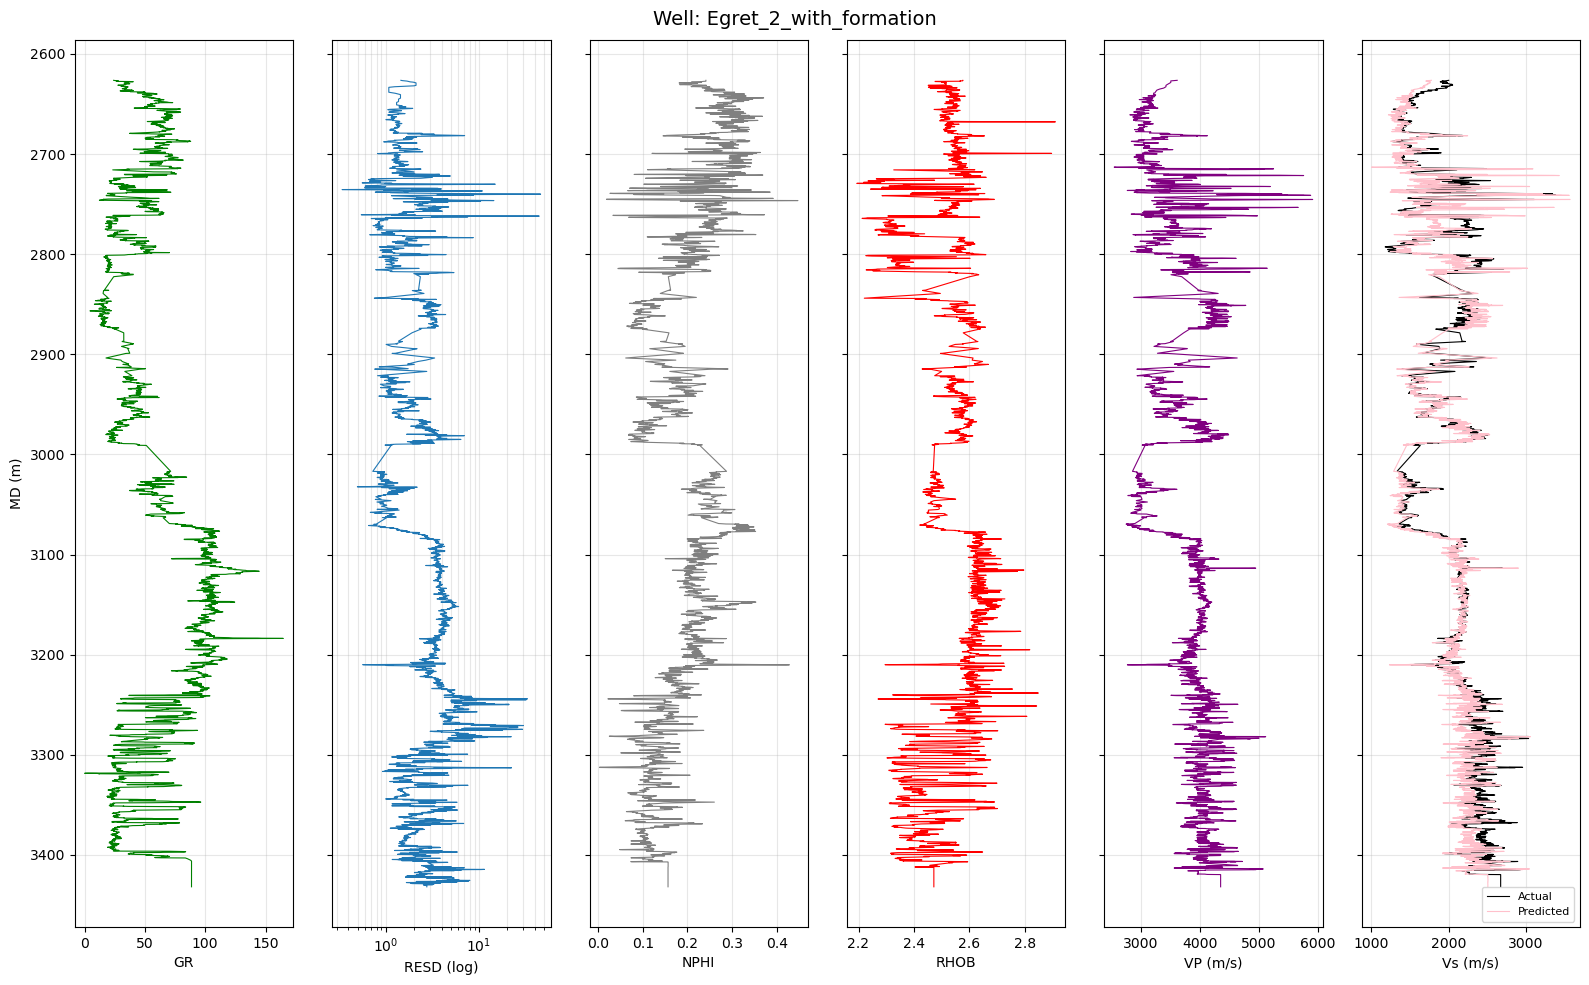

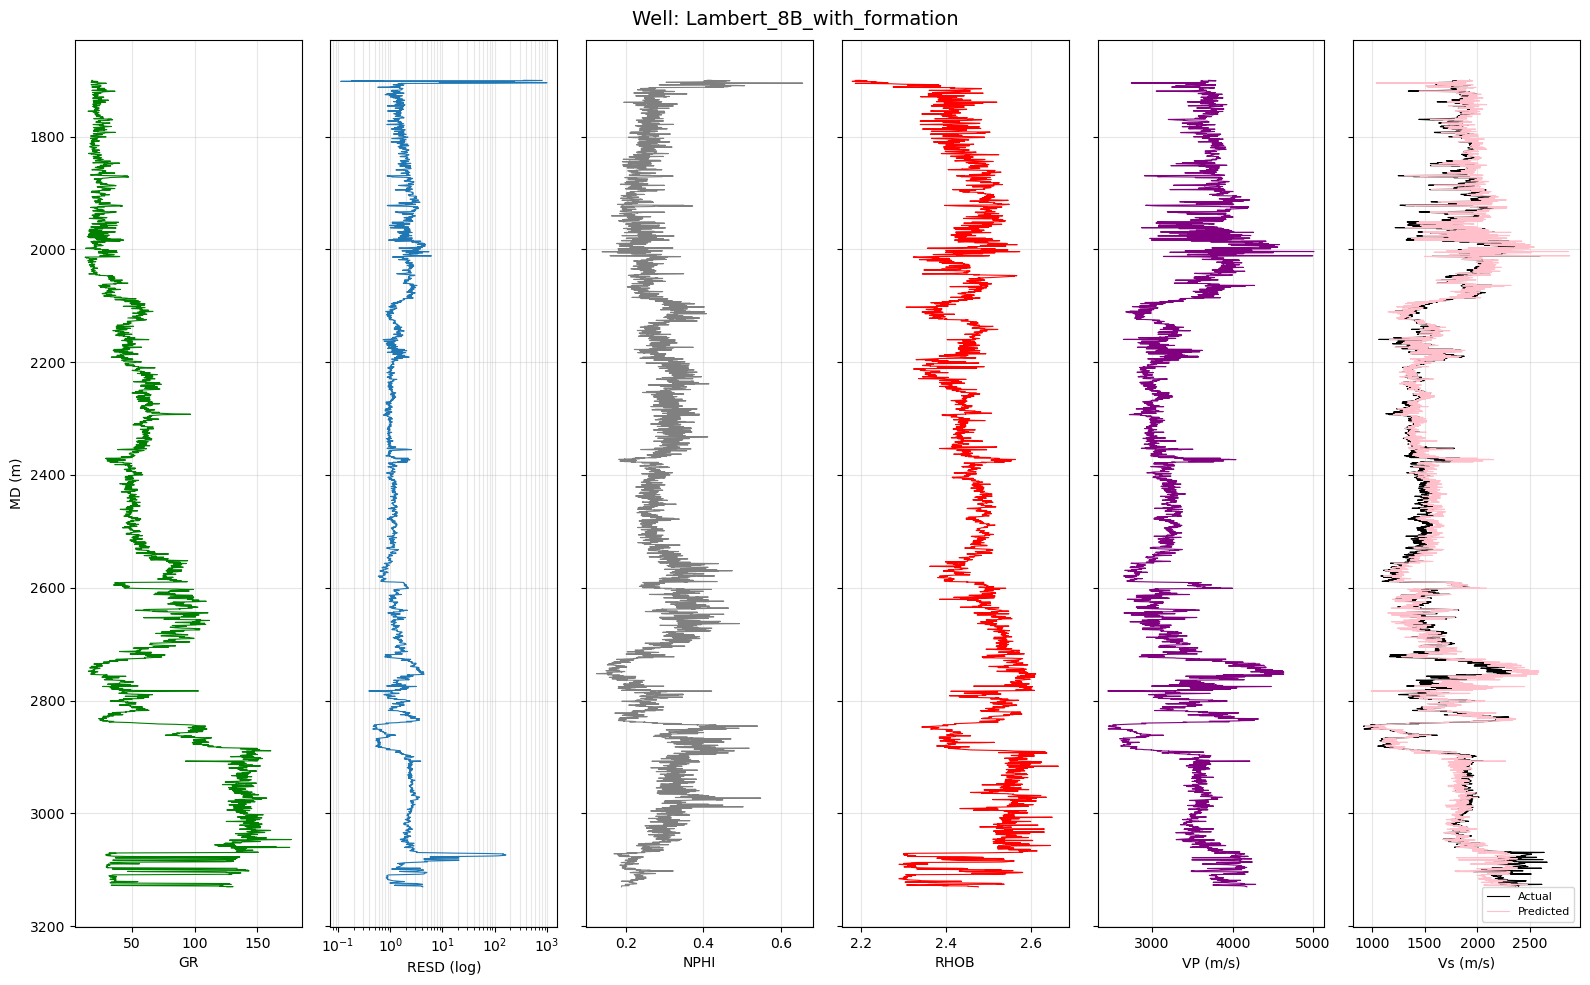

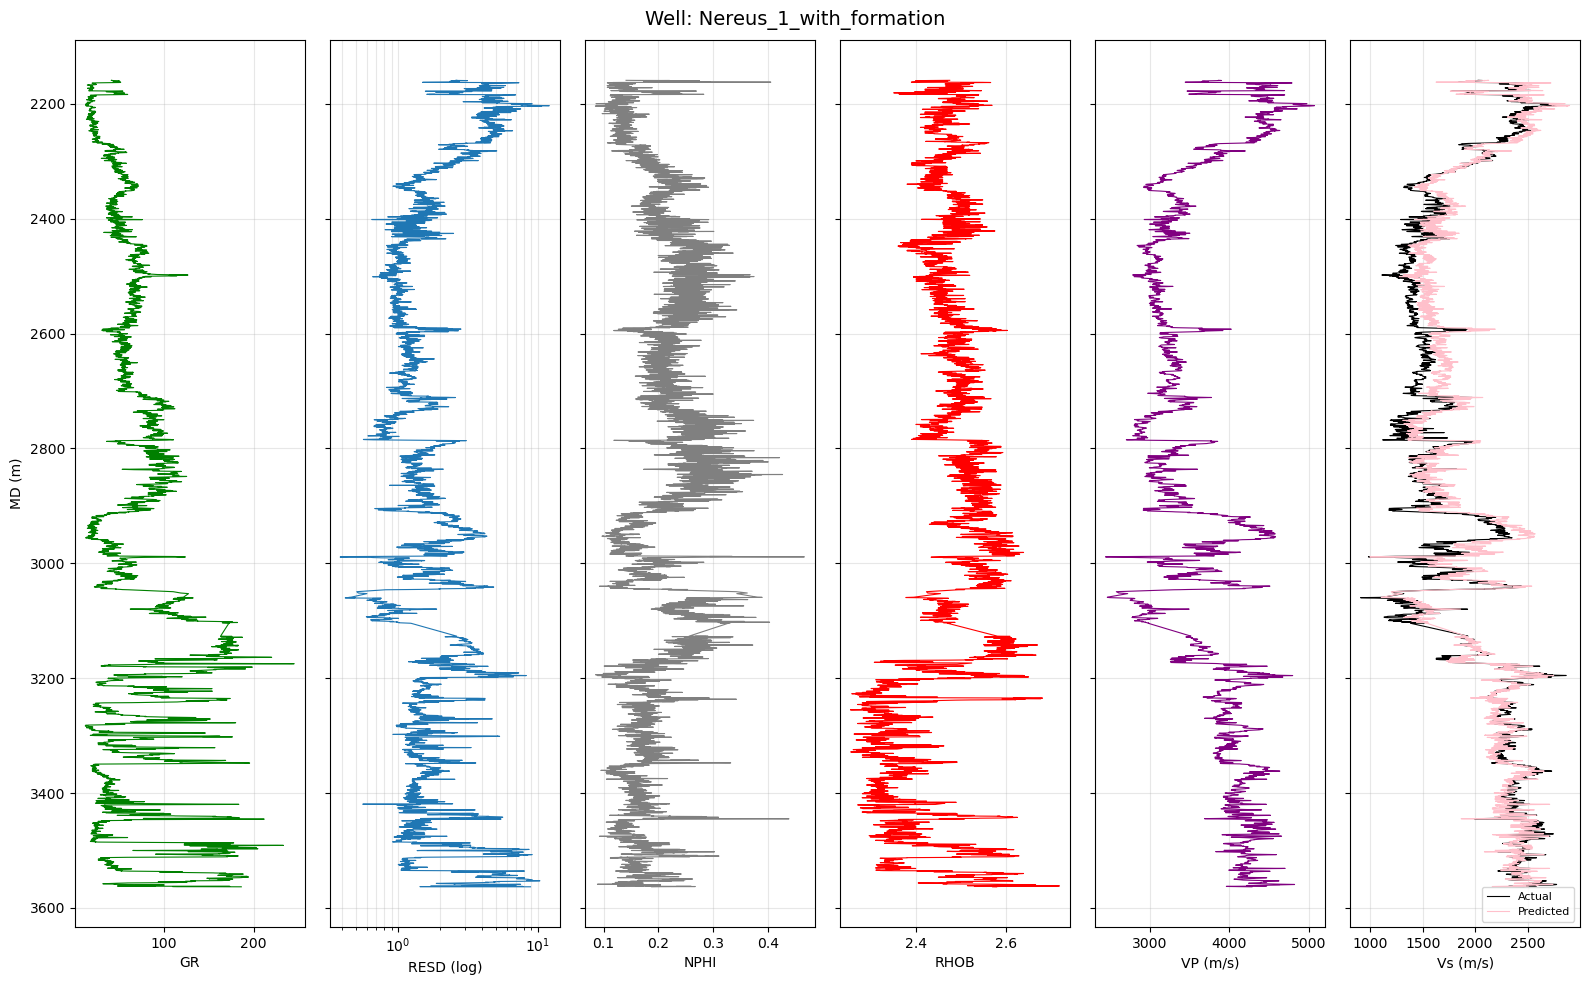

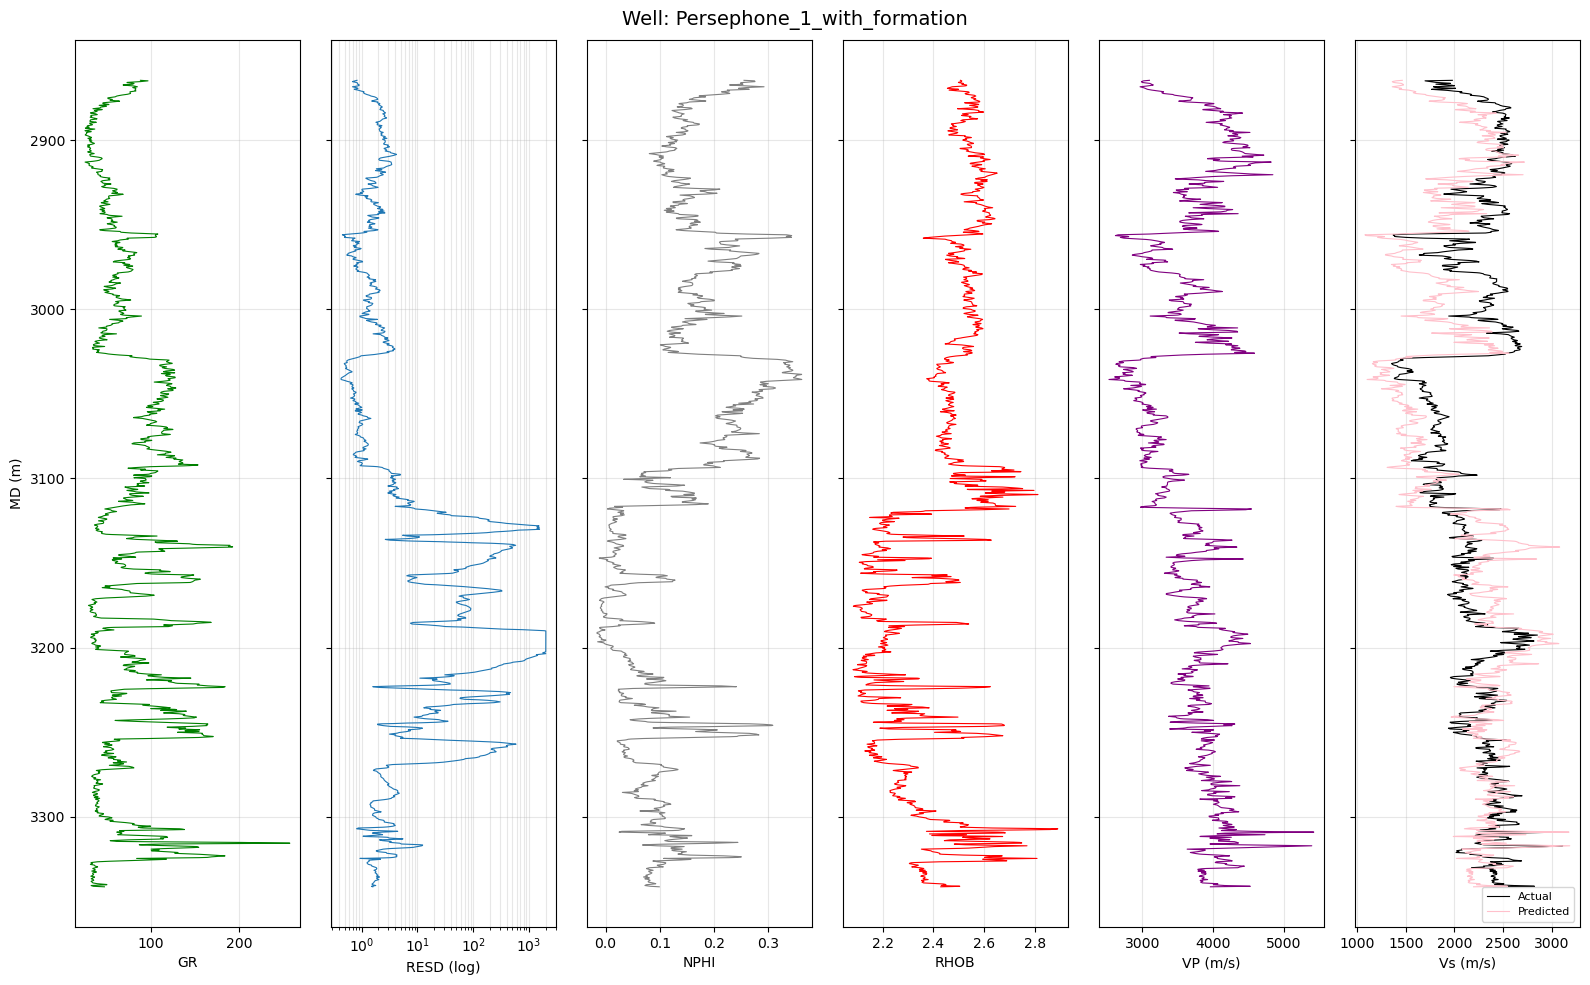

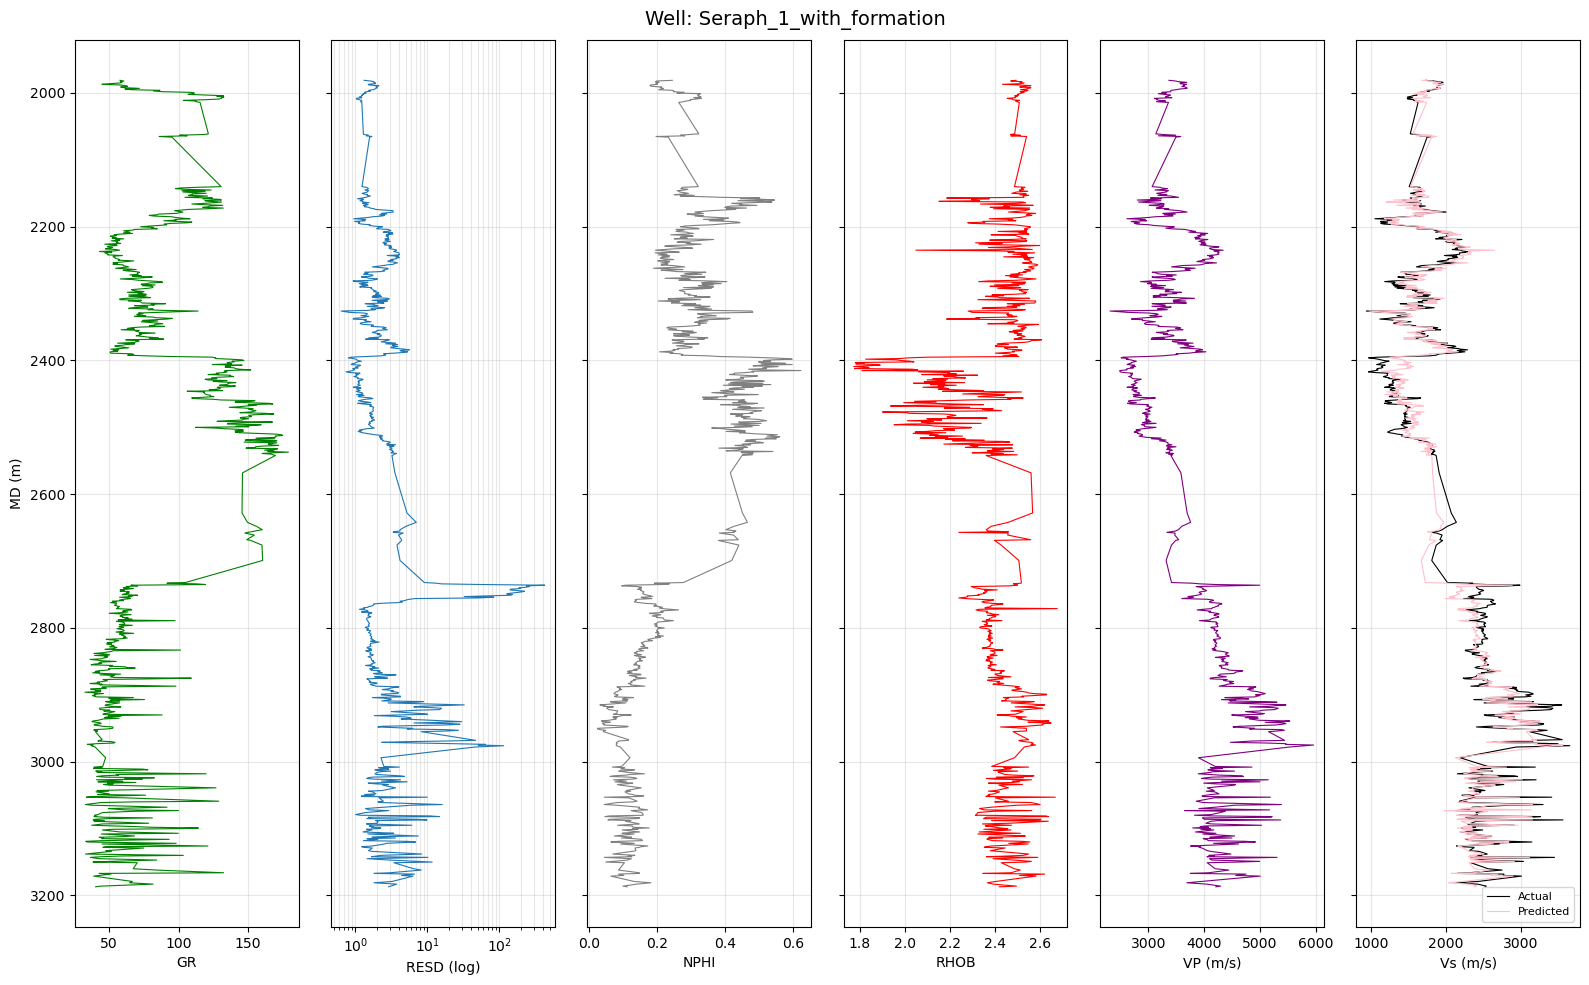

In [11]:
for plot_well in measured_wells:

    train_df = data_df[(data_df['Well Name'] != plot_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == plot_well].copy()

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])

    base_models = [
        ('linear', LinearRegression()),
        ('ridge', Ridge(alpha=1.0)),
        ('lasso', Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)),
    ]

    model = StackingRegressor(
        estimators=base_models,
        final_estimator=Ridge(alpha=1.0),
        cv=5
    )
    model.fit(X_train, train_df[target_reg])
    val_df['VS_PRED'] = model.predict(X_val)

    depth = val_df['MD']

    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(16, 10), sharey=True)

    # Track 1 - GR
    axes[0].plot(val_df['GR_EDITED'], depth, color='green', lw=0.8)
    axes[0].set_xlabel('GR')
    axes[0].grid(alpha=0.3)

    # Track 2 - Resistivity (log scale is standard convention for resistivity)
    axes[1].plot(val_df['RESD_EDITED'], depth, color='tab:blue', lw=0.8)
    axes[1].set_xscale('log')
    axes[1].set_xlabel('RESD (log)')
    axes[1].grid(alpha=0.3, which='both')

    # Track 3 - NPHI (neutron porosity)
    axes[2].plot(val_df['NPHI_EDITED'], depth, color='gray', lw=0.8)
    axes[2].set_xlabel('NPHI')
    axes[2].grid(alpha=0.3)

    # Track 4 - RHOB (density)
    axes[3].plot(val_df['RHOB_EDITED'], depth, color='red', lw=0.8)
    axes[3].set_xlabel('RHOB')
    axes[3].grid(alpha=0.3)

    # Track 5 - VP (compressional velocity, strongest predictor)
    axes[4].plot(val_df['VP_EDITED'], depth, color='purple', lw=0.8)
    axes[4].set_xlabel('VP (m/s)')
    axes[4].grid(alpha=0.3)

    # Track 6 - Actual vs Predicted Vs
    axes[5].plot(val_df[target_reg], depth, color='black', lw=0.8, label='Actual')
    axes[5].plot(val_df['VS_PRED'], depth, color='pink', lw=0.8, label='Predicted')
    axes[5].set_xlabel('Vs (m/s)')
    axes[5].legend(fontsize=8, loc='lower right')
    axes[5].grid(alpha=0.3)

    axes[0].invert_yaxis()
    axes[0].set_ylabel('MD (m)')
    fig.suptitle(f'Well: {plot_well}', fontsize=14)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"stacked_multitrack_{plot_well.replace('_with_formation', '')}.png", dpi=300, bbox_inches='tight')
    plt.show()

### Residual diagnostics (Stacked Ensemble, pooled across 5 wells)

Residual (predicted minus actual) plotted against actual Vs and against depth -- checks for bias that a single averaged R²/RMSE can hide, e.g. systematic under/over-prediction at particular Vs ranges or depths.

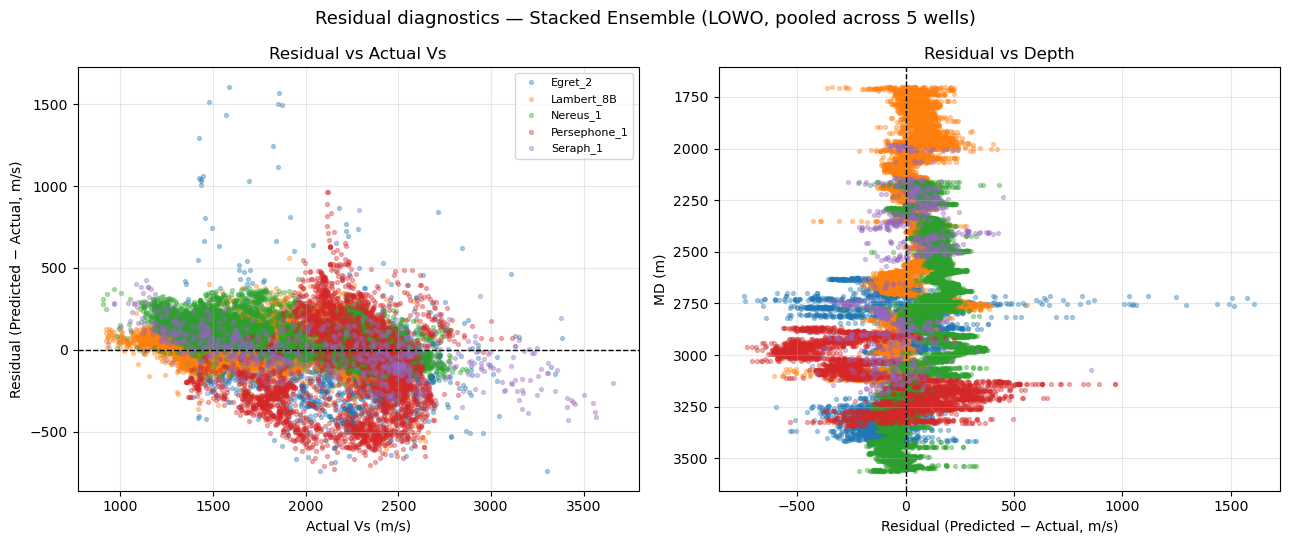

Mean residual: 10.54 m/s   Std residual: 161.93 m/s


In [12]:
actual_all, predicted_all, depth_all, well_all = [], [], [], []

for val_well in measured_wells:
    train_df = data_df[(data_df['Well Name'] != val_well) & (data_df['Well Name'].isin(measured_wells))]
    val_df = data_df[data_df['Well Name'] == val_well]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[features_reg])
    X_val = scaler.transform(val_df[features_reg])

    base_models = [
        ('linear', LinearRegression()),
        ('ridge', Ridge(alpha=1.0)),
        ('lasso', Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)),
    ]

    model = StackingRegressor(estimators=base_models, final_estimator=Ridge(alpha=1.0), cv=5)
    model.fit(X_train, train_df[target_reg])
    pred = model.predict(X_val)

    actual_all.extend(val_df[target_reg].values)
    predicted_all.extend(pred)
    depth_all.extend(val_df['MD'].values)
    well_all.extend([val_well.replace('_with_formation', '')] * len(val_df))

resid_df = pd.DataFrame({'Actual': actual_all, 'Predicted': predicted_all, 'Depth': depth_all, 'Well': well_all})
resid_df['Residual'] = resid_df['Predicted'] - resid_df['Actual']

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for well_name, group in resid_df.groupby('Well'):
    axes[0].scatter(group['Actual'], group['Residual'], s=8, alpha=0.35, label=well_name)
axes[0].axhline(0, color='black', lw=1, ls='--')
axes[0].set_xlabel('Actual Vs (m/s)')
axes[0].set_ylabel('Residual (Predicted − Actual, m/s)')
axes[0].set_title('Residual vs Actual Vs')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

for well_name, group in resid_df.groupby('Well'):
    axes[1].scatter(group['Residual'], group['Depth'], s=8, alpha=0.35, label=well_name)
axes[1].axvline(0, color='black', lw=1, ls='--')
axes[1].invert_yaxis()
axes[1].set_xlabel('Residual (Predicted − Actual, m/s)')
axes[1].set_ylabel('MD (m)')
axes[1].set_title('Residual vs Depth')
axes[1].grid(alpha=0.3)

fig.suptitle('Residual diagnostics — Stacked Ensemble (LOWO, pooled across 5 wells)', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "stacked_residual_diagnostics.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Mean residual: {resid_df['Residual'].mean():.2f} m/s   Std residual: {resid_df['Residual'].std():.2f} m/s")


# Part 2 — Train on Measured Wells, Predict Modelled-Only Wells

Same logic as every other notebook: train **one final stacked ensemble** using all 5 measured-Vs wells at once (no rotation, since none of them are being tested), then use it to predict Vs for Angel_1, Angel_3, and Wanaea_11A.

Comparison columns are labelled "vs SLB estimate" on purpose — `VS_EDITED_V2` for these 3 wells is SLB's own GC-based estimate, not a real measurement, so this is an agreement check, not a validated accuracy score.

## 6. Build training/prediction sets

In [13]:
train_df = data_df[data_df['Well Name'].isin(measured_wells)]
predict_df = data_df[data_df['Well Name'].isin(modelled_wells)].copy()

print("Training samples (5 measured wells):", len(train_df))
print("Samples to predict (3 modelled-only wells):", len(predict_df))

Training samples (5 measured wells): 26749
Samples to predict (3 modelled-only wells): 21949


## 7. Stacked Ensemble — train on measured, predict modelled-only

In [14]:
scaler_final = StandardScaler()
X_train_scaled = scaler_final.fit_transform(train_df[features_reg])
X_predict_scaled = scaler_final.transform(predict_df[features_reg])

base_models_final = [
    ('linear', LinearRegression()),
    ('ridge', Ridge(alpha=1.0)),
    ('lasso', Lasso(alpha=best_alpha, max_iter=20000, tol=1e-3)),
]

model_final_stack = StackingRegressor(
    estimators=base_models_final,
    final_estimator=Ridge(alpha=1.0),
    cv=5
)
model_final_stack.fit(X_train_scaled, train_df[target_reg])

predict_df['VS_PRED_STACK'] = model_final_stack.predict(X_predict_scaled)

In [15]:
results = []

for well in modelled_wells:
    well_df = predict_df[predict_df['Well Name'] == well]

    results.append({
        'Well': well,
        'R2 vs SLB estimate': r2_score(well_df[target_reg], well_df['VS_PRED_STACK']),
        'RMSE vs SLB estimate': np.sqrt(mean_squared_error(well_df[target_reg], well_df['VS_PRED_STACK'])),
        'MAE vs SLB estimate': mean_absolute_error(well_df[target_reg], well_df['VS_PRED_STACK'])
    })

results_vs_slb_vs_pred_stack = pd.DataFrame(results)
results_vs_slb_vs_pred_stack

,Well,R2 vs SLB estimate,RMSE vs SLB estimate,MAE vs SLB estimate
0,Angel_1_with_formation,0.818021,187.625145,154.465288
1,Angel_3_with_formation,0.866358,168.692782,135.684582
2,Wanaea_11A_with_formation,0.839942,110.113507,76.325579


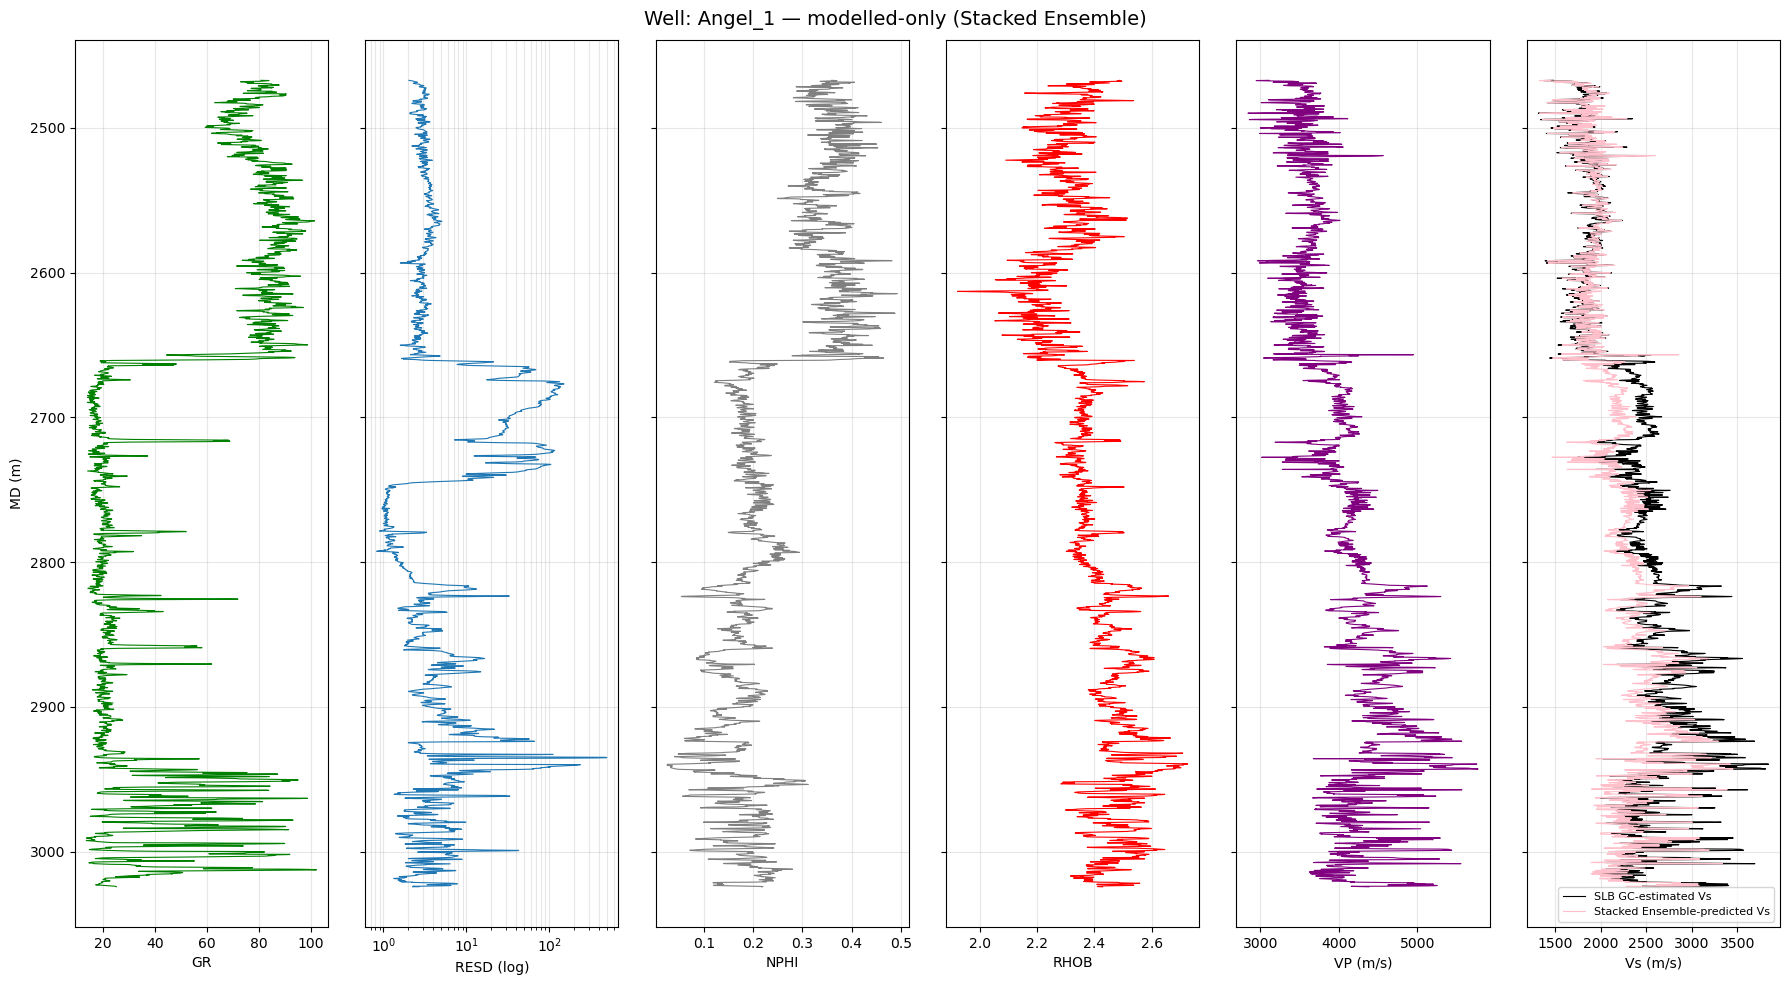

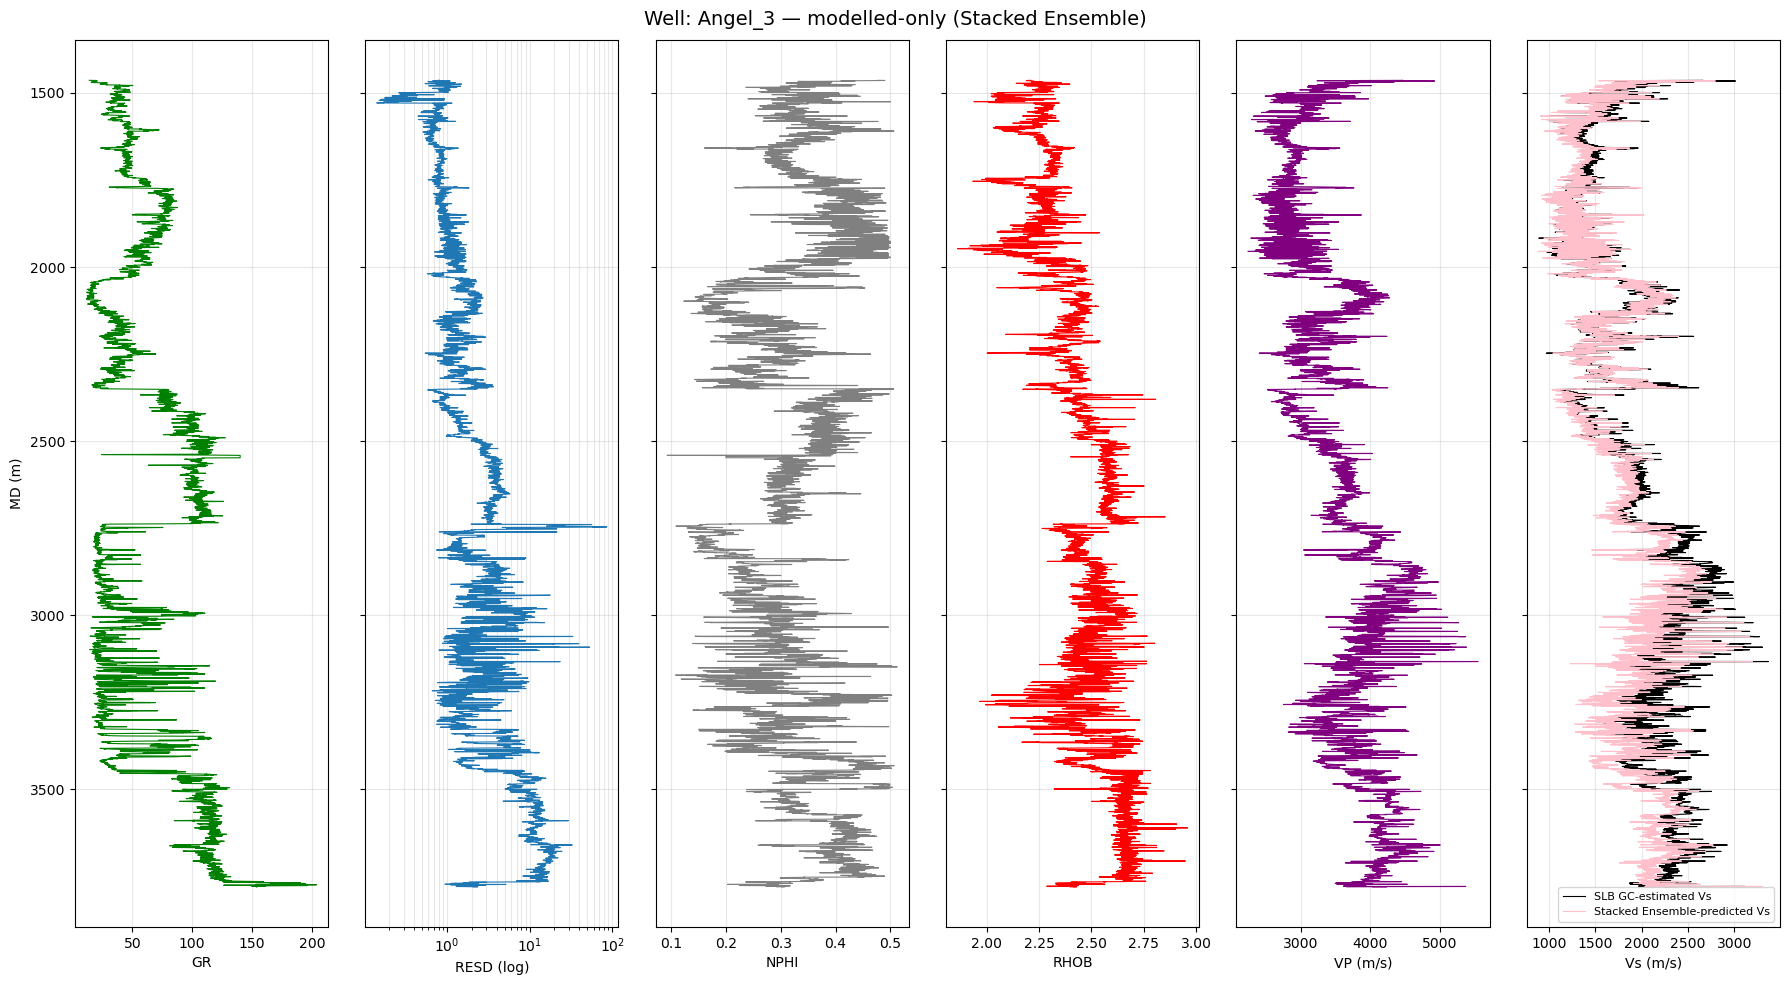

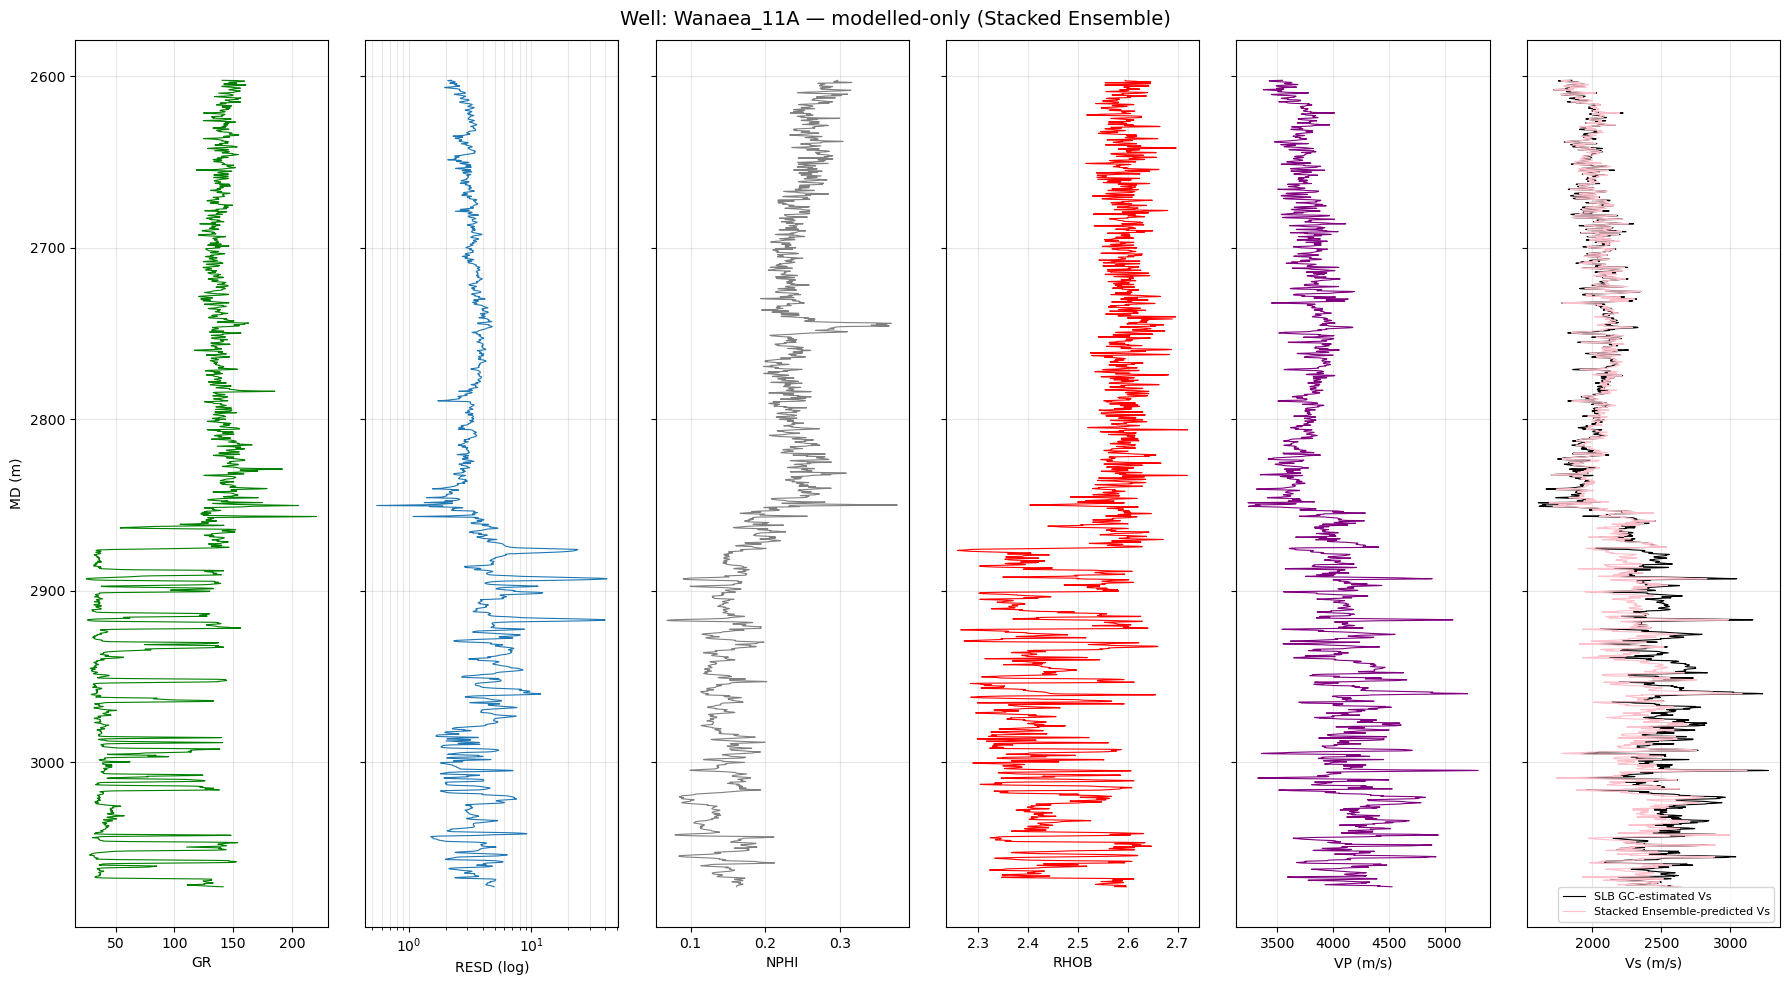

In [16]:
for well in modelled_wells:

    well_df = predict_df[predict_df['Well Name'] == well]
    depth = well_df['MD']

    fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(18, 10), sharey=True)

    axes[0].plot(well_df['GR_EDITED'], depth, color='green', lw=0.8)
    axes[0].set_xlabel('GR')
    axes[0].grid(alpha=0.3)

    axes[1].plot(well_df['RESD_EDITED'], depth, color='tab:blue', lw=0.8)
    axes[1].set_xscale('log')
    axes[1].set_xlabel('RESD (log)')
    axes[1].grid(alpha=0.3, which='both')

    axes[2].plot(well_df['NPHI_EDITED'], depth, color='gray', lw=0.8)
    axes[2].set_xlabel('NPHI')
    axes[2].grid(alpha=0.3)

    axes[3].plot(well_df['RHOB_EDITED'], depth, color='red', lw=0.8)
    axes[3].set_xlabel('RHOB')
    axes[3].grid(alpha=0.3)

    axes[4].plot(well_df['VP_EDITED'], depth, color='purple', lw=0.8)
    axes[4].set_xlabel('VP (m/s)')
    axes[4].grid(alpha=0.3)

    axes[5].plot(well_df[target_reg], depth, color='black', lw=0.8, label='SLB GC-estimated Vs')
    axes[5].plot(well_df['VS_PRED_STACK'], depth, color='pink', lw=0.8, label='Stacked Ensemble-predicted Vs')
    axes[5].set_xlabel('Vs (m/s)')
    axes[5].legend(fontsize=8, loc='lower right')
    axes[5].grid(alpha=0.3)

    axes[0].invert_yaxis()
    axes[0].set_ylabel('MD (m)')
    fig.suptitle(f'Well: {well.replace("_with_formation", "")} — modelled-only (Stacked Ensemble)', fontsize=14)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"stacked_part2_multitrack_{well.replace('_with_formation', '')}.png", dpi=300, bbox_inches='tight')
    plt.show()